# 1 · Structure and temperature: the Utah FORGE geothermal site

**KAI-GeoEnergy · KAI Reservoir Lab · Utah FORGE, Milford, Utah (USA)**

**Question.** Where is the hot granitoid under the basin fill, how hot is it, and can the 3-D temperature model be trusted at the deep well?

**Data.** Utah FORGE is the U.S. Department of Energy's field laboratory for enhanced geothermal systems (EGS). Its data are public on the DOE Geothermal Data Repository (GDR) under CC BY 4.0:
* the Phase 2 3-D model export from Leapfrog Geothermal (GDR 1205, Podgorney 2020, DOI [10.15121/1605155](https://doi.org/10.15121/1605155)): lithology on a 2.5 × 2.5 × 2.75 km grid of 50 m cells, and temperature, pressure and stress at its nodes;
* the temperature and pressure log of deep well **58-32 (MU-ESW1)** run on 8 November 2018 (GDR 1101, DOI [10.15121/1493769](https://doi.org/10.15121/1493769));
* the surveyed well-head coordinates of December 2021 (GDR 1358).

This folder holds only values derived from them (`data/`). `rebuild_data.py` downloads the GDR files, checks their SHA-256 and rebuilds `data/`. *Credit: Utah FORGE, U.S. Department of Energy, via the Geothermal Data Repository (OpenEI), CC BY 4.0.*

**Method.** The granitoid surface is the top of the highest granitoid cell in each column. Temperature at the well is interpolated from the model nodes (bilinear across the map, linear with depth). The 58-32 log is converted from measured depth below the kelly bushing (21.5 ft above ground) to depth below ground; the well is treated as vertical (its survey stays within about 40 m of the well head, less than one cell).

**What this check is, and is not.** The source model was built with data from 58-32, so the comparison is a consistency check of the export, the georeferencing and the interpolation. It is not a blind test.

In [1]:
import json, pathlib, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import forge_tools as ft
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
                     "axes.titleweight": "bold", "axes.titlesize": 11, "legend.frameon": False, "savefig.bbox": "tight", "savefig.facecolor": "white"})
GOLD, CHARCOAL, FILL, GRANITE, BLUE = "#c9a227", "#26292e", "#d8c7a3", "#b5838d", "#2a78d6"     # KAI energy palette
pathlib.Path("results").mkdir(exist_ok=True); pathlib.Path("figures").mkdir(exist_ok=True)

m = np.load("data/forge_model.npz")
granite, T, P, depth = m["granite"], m["T_c"].astype(float), m["p_mpa"].astype(float), m["depth_m"].astype(float)
tr = json.loads(str(m["transform"]))
wells = pd.read_csv("data/wells.csv").set_index("well")
log = pd.read_csv("data/well_58_32_log_2018.csv")
engine = json.loads(pathlib.Path("results/kai_engine_results.json").read_text())
zn = ft.Z_BOTTOM + np.arange(ft.NZ + 1) * ft.CELL            # node elevations, m a.s.l. (index 0 = deepest)
xn = np.arange(ft.NXY + 1) * ft.CELL                          # node positions along the model axes, m
ground = (zn[:, None, None] + depth).mean(axis=0)             # ground elevation above each node column
print(f"{granite.size:,} cells of {ft.CELL:.0f} m: {granite.sum():,} granitoid, {(~granite).sum():,} basin fill")
print(f"temperature {T.min():.1f} to {T.max():.1f} °C; model +x axis points to azimuth {tr['azimuth_x_deg']:.1f}°")

137,500 cells of 50 m: 98,610 granitoid, 38,890 basin fill
temperature 54.0 to 262.7 °C; model +x axis points to azimuth 115.0°


## The grid on the map

The model's local metres are rotated against UTM. A least-squares fit of the 137,500 cell centres in both coordinate systems recovers the rotation and checks it: the ground elevation the model implies at 58-32 should match the surveyed well head.

In [2]:
w = wells.loc["58-32"]
x58, y58 = w.x_model_m, w.y_model_m
g58 = float(ft.column_profile(zn[:, None, None] + depth, x58, y58).mean())
geo = {"azimuth_x_deg": tr["azimuth_x_deg"], "fit_residual_m": tr["max_residual_m"], "x58_m": x58, "y58_m": y58,
       "model_ground_m": g58, "surveyed_ground_m": w.elev_m, "difference_m": g58 - w.elev_m}
print(json.dumps({k: round(v, 3) for k, v in geo.items()}, indent=1))

{
 "azimuth_x_deg": 115.0,
 "fit_residual_m": 0.0,
 "x58_m": 1811.82,
 "y58_m": 1066.44,
 "model_ground_m": 1685.407,
 "surveyed_ground_m": 1684.772,
 "difference_m": 0.634
}


## The granitoid under the basin fill

{
 "depth_to_granite_min_m": 533.1,
 "depth_to_granite_max_m": 1911.3,
 "depth_to_granite_mean_m": 1189.8,
 "granite_top_58_32_elev_m": 700.0,
 "depth_to_granite_58_32_m": 985.4,
 "granite_volume_km3": 12.3
}


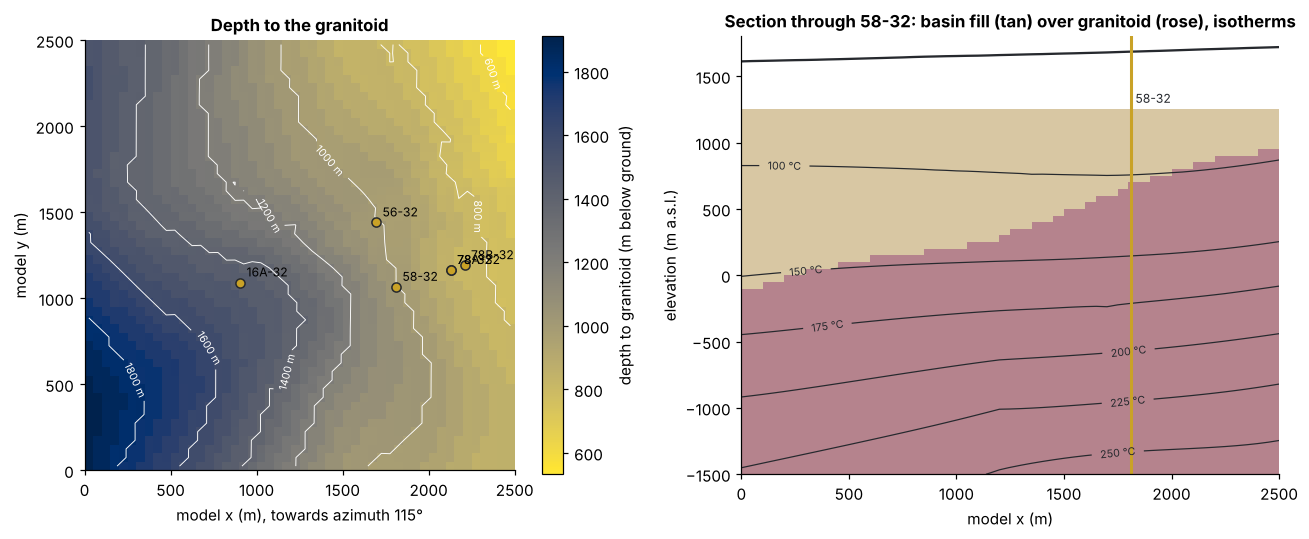

In [3]:
top = ft.granite_top(granite)                                     # (50, 50) elevation of the granitoid top
gcell = 0.25 * (ground[:-1, :-1] + ground[1:, :-1] + ground[:-1, 1:] + ground[1:, 1:])
d2g = gcell - top
i58, j58 = int(x58 // ft.CELL), int(y58 // ft.CELL)
structure = {"depth_to_granite_min_m": float(d2g.min()), "depth_to_granite_max_m": float(d2g.max()), "depth_to_granite_mean_m": float(d2g.mean()),
             "granite_top_58_32_elev_m": float(top[j58, i58]), "depth_to_granite_58_32_m": float(g58 - top[j58, i58]),
             "granite_volume_km3": float(granite.sum() * ft.CELL**3 / 1e9)}
print(json.dumps({k: round(v, 1) for k, v in structure.items()}, indent=1))

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ext = [0, 2500, 0, 2500]
im = ax[0].imshow(d2g, origin="lower", extent=ext, cmap="cividis_r"); fig.colorbar(im, ax=ax[0], label="depth to granitoid (m below ground)")
cs = ax[0].contour(np.arange(25, 2500, 50), np.arange(25, 2500, 50), d2g, levels=range(600, 2000, 200), colors="white", linewidths=0.6)
ax[0].clabel(cs, fmt="%d m", fontsize=7)
for name, r in wells.iterrows():
    if 0 <= r.x_model_m <= 2500 and 0 <= r.y_model_m <= 2500:
        ax[0].plot(r.x_model_m, r.y_model_m, "o", color=GOLD, mec=CHARCOAL, ms=6); ax[0].annotate(name, (r.x_model_m, r.y_model_m), xytext=(4, 4), textcoords="offset points", fontsize=8)
ax[0].set_title("Depth to the granitoid"); ax[0].set_xlabel(f"model x (m), towards azimuth {tr['azimuth_x_deg']:.0f}°"); ax[0].set_ylabel("model y (m)")
# cross-section along x through 58-32
sec = granite[:, j58, :]
ax[1].imshow(sec, origin="lower", extent=[0, 2500, ft.Z_BOTTOM, ft.Z_TOP], aspect="auto", cmap=ListedColormap([FILL, GRANITE]))
Tsec = 0.5 * (T[:, j58, :] + T[:, j58 + 1, :])
cs = ax[1].contour(xn, zn, Tsec, levels=[100, 150, 175, 200, 225, 250], colors=CHARCOAL, linewidths=0.8); ax[1].clabel(cs, fmt="%d °C", fontsize=7)
ax[1].plot(xn, 0.5 * (ground[j58] + ground[j58 + 1]), color=CHARCOAL, lw=1.5)
ax[1].axvline(x58, color=GOLD, lw=2); ax[1].text(x58 + 20, 1300, "58-32", color=CHARCOAL, fontsize=8)
ax[1].set_ylim(ft.Z_BOTTOM, 1800); ax[1].set_xlabel("model x (m)"); ax[1].set_ylabel("elevation (m a.s.l.)")
ax[1].set_title("Section through 58-32: basin fill (tan) over granitoid (rose), isotherms")
fig.tight_layout(); fig.savefig("figures/forge_structure.png")

## Temperature in 3-D

The depth of the 175 °C isotherm (the bottom of the usual EGS temperature window) across the site, and how much granitoid is hotter than each temperature.

granitoid volume hotter than (km³): {'150': 10.44, '175': 7.94, '200': 5.25, '225': 2.43}
175 °C isotherm: 1653 to 2149 m below ground


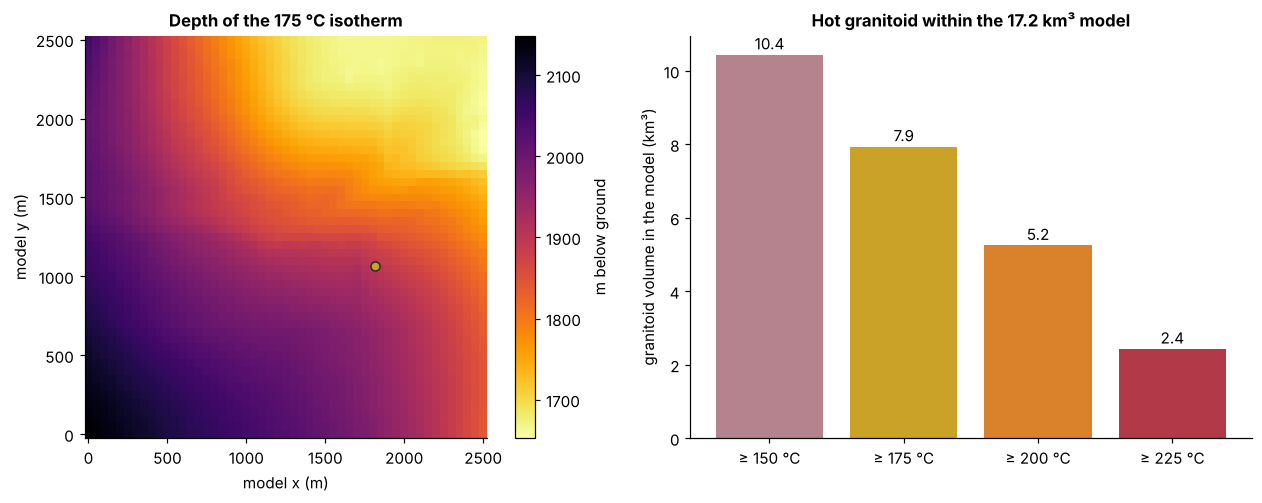

In [4]:
def iso_map(t_iso):
    out = np.full((ft.NXY + 1, ft.NXY + 1), np.nan)
    for j in range(ft.NXY + 1):
        for i in range(ft.NXY + 1):
            v = ft.isotherm_depth(T[:, j, i], depth[:, j, i], t_iso)
            out[j, i] = np.nan if v is None else v
    return out

iso175 = iso_map(175.0)
Tc = ft.cell_average(T)
vol = {str(t): float((granite & (Tc >= t)).sum() * ft.CELL**3 / 1e9) for t in (150, 175, 200, 225)}
print("granitoid volume hotter than (km³):", {k: round(v, 2) for k, v in vol.items()})
print(f"175 °C isotherm: {np.nanmin(iso175):.0f} to {np.nanmax(iso175):.0f} m below ground")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
im = ax[0].imshow(iso175, origin="lower", extent=[-25, 2525, -25, 2525], cmap="inferno_r"); fig.colorbar(im, ax=ax[0], label="m below ground")
ax[0].plot(x58, y58, "o", color=GOLD, mec=CHARCOAL); ax[0].set_title("Depth of the 175 °C isotherm"); ax[0].set_xlabel("model x (m)"); ax[0].set_ylabel("model y (m)")
ts = [150, 175, 200, 225]
ax[1].bar([f"≥ {t} °C" for t in ts], [vol[str(t)] for t in ts], color=[GRANITE, GOLD, "#d9822b", "#b23a48"])
for k_, t in enumerate(ts):
    ax[1].text(k_, vol[str(t)] + 0.15, f"{vol[str(t)]:.1f}", ha="center")
ax[1].set_ylabel("granitoid volume in the model (km³)"); ax[1].set_title("Hot granitoid within the 17.2 km³ model")
fig.tight_layout(); fig.savefig("figures/forge_temperature.png")

## The model against the 58-32 temperature log (8 November 2018)

{
 "compared_from_m": 440.0,
 "compared_to_m": 2290.0,
 "n": 186,
 "bias_c": 1.38,
 "rmse_c": 1.68,
 "max_abs_c": 4.36,
 "gradient_basin_fill_log": 94.86,
 "gradient_basin_fill_model": 88.67,
 "gradient_granite_log": 71.93,
 "gradient_granite_model": 73.19,
 "T_log_max_c": 199.33,
 "log_max_depth_m": 2295.0
}
isotherm depths at 58-32 (m below ground): {'150': 1542, '175': 1899, '200': 2257, '225': 2633}


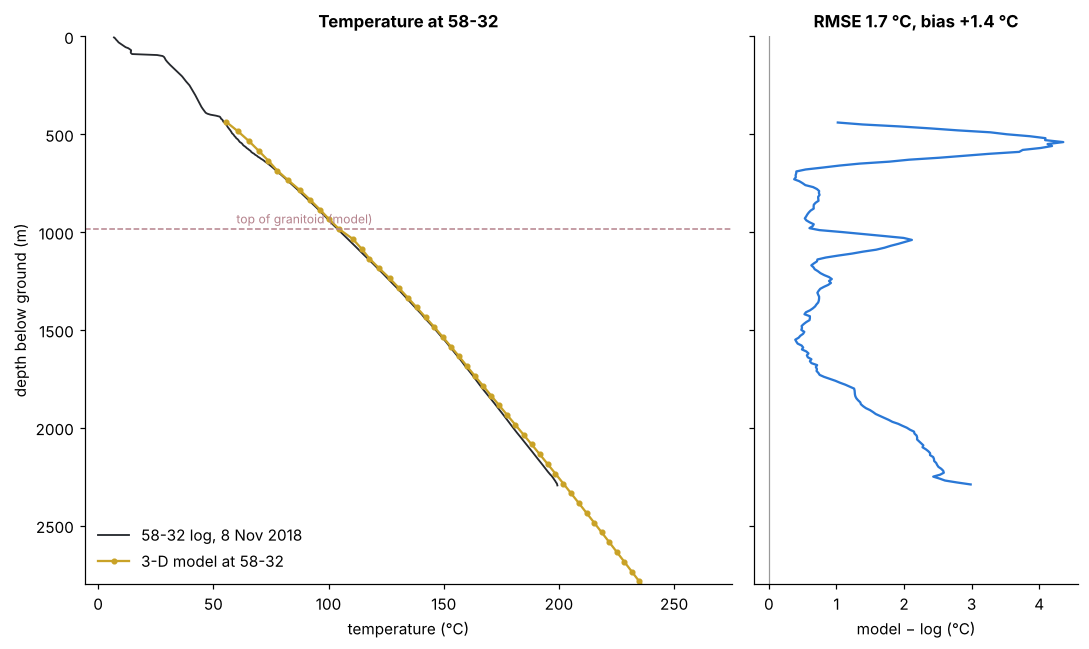

In [5]:
Tcol = ft.column_profile(T, x58, y58); dcol = g58 - zn                   # bottom → top
dd = np.arange(np.ceil(dcol.min() / 10) * 10, min(dcol.max(), log.depth_m.max()), 10.0)
T_log = np.interp(dd, log.depth_m, log.T_c); T_mod = np.interp(dd, dcol[::-1], Tcol[::-1]); diff = T_mod - T_log
in_gr = dd > structure["depth_to_granite_58_32_m"]
grad = lambda d, t: float(np.polyfit(d, t, 1)[0] * 1000)
check = {"compared_from_m": float(dd[0]), "compared_to_m": float(dd[-1]), "n": int(len(dd)), "bias_c": float(diff.mean()),
         "rmse_c": float(np.sqrt(np.mean(diff**2))), "max_abs_c": float(np.abs(diff).max()),
         "gradient_basin_fill_log": grad(dd[~in_gr], T_log[~in_gr]), "gradient_basin_fill_model": grad(dd[~in_gr], T_mod[~in_gr]),
         "gradient_granite_log": grad(dd[in_gr], T_log[in_gr]), "gradient_granite_model": grad(dd[in_gr], T_mod[in_gr]),
         "T_log_max_c": float(log.T_c.max()), "log_max_depth_m": float(log.depth_m.max())}
print(json.dumps({k: round(v, 2) for k, v in check.items()}, indent=1))
iso58 = {str(t): ft.isotherm_depth(Tcol, dcol, t) for t in (150, 175, 200, 225)}
print("isotherm depths at 58-32 (m below ground):", {k: round(v) for k, v in iso58.items()})

fig, ax = plt.subplots(1, 2, figsize=(10, 6), sharey=True, gridspec_kw={"width_ratios": [2, 1]})
ax[0].plot(log.T_c, log.depth_m, color=CHARCOAL, lw=1.2, label="58-32 log, 8 Nov 2018")
ax[0].plot(Tcol, dcol, "o-", color=GOLD, ms=3, label="3-D model at 58-32")
ax[0].axhline(structure["depth_to_granite_58_32_m"], color=GRANITE, ls="--", lw=1); ax[0].text(60, structure["depth_to_granite_58_32_m"] - 30, "top of granitoid (model)", color=GRANITE, fontsize=8)
ax[0].invert_yaxis(); ax[0].set_xlabel("temperature (°C)"); ax[0].set_ylabel("depth below ground (m)"); ax[0].legend(loc="lower left")
ax[0].set_title("Temperature at 58-32"); ax[0].set_ylim(2800, 0)
ax[1].plot(diff, dd, color=BLUE); ax[1].axvline(0, color="#999", lw=0.8); ax[1].set_xlabel("model − log (°C)")
ax[1].set_title(f"RMSE {check['rmse_c']:.1f} °C, bias {check['bias_c']:+.1f} °C")
fig.tight_layout(); fig.savefig("figures/forge_58_32_check.png")

## Pressure and stress

Pore pressure is close to hydrostatic. The source workbook defines the stresses by depth gradients (a normal-faulting regime, Sv > SHmax > Shmin); they are reported as they are defined there, as magnitudes with compression positive.

In [6]:
pc, dc = ft.cell_average(P), ft.cell_average(depth)
pfit = np.polyfit(dc.ravel(), pc.ravel(), 1)
stress = {"pore_pressure_gradient_kpa_m": float(pfit[0] * 1000), **{f"{k}_gradient_kpa_m": v for k, v in ft.STRESS_GRADIENTS_KPA_M.items()},
          **{f"{k}_at_2000m_mpa": v * 2 for k, v in ft.STRESS_GRADIENTS_KPA_M.items()}, "pore_pressure_at_2000m_mpa": float(np.polyval(pfit, 2000))}
print(json.dumps({k: round(v, 2) for k, v in stress.items()}, indent=1))

{
 "pore_pressure_gradient_kpa_m": 8.88,
 "Sv_gradient_kpa_m": 21.56,
 "SHmax_gradient_kpa_m": 17.4,
 "Shmin_gradient_kpa_m": 14.6,
 "Sv_at_2000m_mpa": 43.12,
 "SHmax_at_2000m_mpa": 34.8,
 "Shmin_at_2000m_mpa": 29.2,
 "pore_pressure_at_2000m_mpa": 17.78
}


## Same answer as the KAI engine

The KAI engine (`kai-engine reference forge`) builds the same model from the raw GDR files on its own Reservoir Lab grid. Its results are in `results/kai_engine_results.json`. The notebook stops if its own numbers drift from them.

In [7]:
e = engine
pairs = {
    "rotation azimuth (°)": (geo["azimuth_x_deg"], e["grid"]["transform"]["azimuth_x_deg"], 1e-6),
    "model vs surveyed ground at 58-32 (m)": (geo["difference_m"], e["well_58_32"]["ground_difference_m"], 0.01),
    "depth to granitoid at 58-32 (m)": (structure["depth_to_granite_58_32_m"], e["well_58_32"]["depth_to_granite_m"], 0.01),
    "depth to granitoid, shallowest (m)": (structure["depth_to_granite_min_m"], e["structure"]["depth_to_granite_m"]["min"], 0.01),
    "depth to granitoid, deepest (m)": (structure["depth_to_granite_max_m"], e["structure"]["depth_to_granite_m"]["max"], 0.01),
    "granitoid volume (km³)": (structure["granite_volume_km3"], e["structure"]["granite_volume_km3"], 1e-6),
    "granitoid ≥ 175 °C (km³)": (vol["175"], e["temperature"]["granite_volume_km3_above"]["175"], 0.01),
    "granitoid ≥ 200 °C (km³)": (vol["200"], e["temperature"]["granite_volume_km3_above"]["200"], 0.01),
    "58-32 log RMSE (°C)": (check["rmse_c"], e["well_58_32"]["log"]["rmse_c"], 0.01),
    "58-32 log bias (°C)": (check["bias_c"], e["well_58_32"]["log"]["bias_c"], 0.01),
    "175 °C isotherm at 58-32 (m)": (iso58["175"], e["well_58_32"]["isotherm_depth_m"]["175"], 0.5),
    "pore-pressure gradient (kPa/m)": (stress["pore_pressure_gradient_kpa_m"], e["pressure"]["gradient_kpa_per_m"], 0.01),
}
rows = []
for name, (mine, theirs, tol) in pairs.items():
    assert abs(mine - theirs) <= tol, f"{name}: notebook {mine} vs engine {theirs}"
    rows.append({"quantity": name, "notebook": round(mine, 2), "KAI engine": round(theirs, 2)})
summary = {"georeferencing": geo, "structure": structure, "granite_volume_km3_above": vol, "well_58_32": check,
           "isotherm_depth_58_32_m": iso58, "pressure_stress": stress}
pathlib.Path("results/nb1_structure_temperature.json").write_text(json.dumps(summary, indent=1))
pd.DataFrame(rows)

,quantity,notebook,KAI engine
0,rotation azimuth (°),115.00,115.00
1,model vs surveyed ground at 58-32 (m),0.63,0.63
2,depth to granitoid at 58-32 (m),985.41,985.41
3,"depth to granitoid, shallowest (m)",533.08,533.08
4,"depth to granitoid, deepest (m)",1911.32,1911.32
5,granitoid volume (km³),12.33,12.33
6,granitoid ≥ 175 °C (km³),7.94,7.94
7,granitoid ≥ 200 °C (km³),5.25,5.25
8,58-32 log RMSE (°C),1.68,1.68
9,58-32 log bias (°C),1.38,1.38


## Published numbers

These are the numbers quoted in the README and on the case page. The notebook stops if they change.

In [8]:
published = {"depth_to_granite_58_32_m": 985, "depth_to_granite_min_m": 533, "depth_to_granite_max_m": 1911,
             "rmse_c": 1.7, "bias_c": 1.4, "granite_175_km3": 7.9, "granite_200_km3": 5.2, "iso175_58_32_m": 1899}
now = {"depth_to_granite_58_32_m": structure["depth_to_granite_58_32_m"], "depth_to_granite_min_m": structure["depth_to_granite_min_m"],
       "depth_to_granite_max_m": structure["depth_to_granite_max_m"], "rmse_c": check["rmse_c"], "bias_c": check["bias_c"],
       "granite_175_km3": vol["175"], "granite_200_km3": vol["200"], "iso175_58_32_m": iso58["175"]}
for k, v in published.items():
    assert abs(now[k] - v) <= (0.5 if isinstance(v, int) else 0.05), (k, now[k], v)
print("all published numbers reproduced")

all published numbers reproduced


## What this gives the Reservoir Lab

* A georeferenced structural model: the granitoid surface lies **533–1,911 m** below ground across the site and **985 m** at 58-32 (at the 50 m resolution of the source grid).
* A temperature model that agrees with the 2018 log of 58-32 to **1.7 °C** RMSE (bias +1.4 °C) between 440 and 2,290 m. The basin fill heats up faster with depth than the granitoid in both.
* **7.9 km³** of granitoid hotter than 175 °C and **5.2 km³** hotter than 200 °C inside the model volume; at 58-32 the 175 °C isotherm is about **1,900 m** below ground.
* Initial pressure and stress for the flow and stress simulations of notebooks 2 and 3.

**Limits.** The temperature model is the source model, not a KAI interpretation; its accuracy away from the deep wells is not tested here. The stresses are depth gradients from the source workbook, not a stress model. The 50 m cells place the granitoid contact to ±25 m.

*References:* Podgorney, R. (2020). Utah FORGE: Data for 3-D Model Development — Lithology, Temperature, Pressure, and Stress. GDR, DOI 10.15121/1605155 · Utah FORGE (2018). Milford Deep Test Well 58-32 (MU-ESW1) Pressure and Temperature Logs. GDR, DOI 10.15121/1493769 · Utah FORGE (2021). Updated Well, Well Pad, and Seismic Station GPS Coordinates. GDR submission 1358.